# Week 4: Logistic Regression and Feature Scaling
**Rupal Paliwal, Mod C, Semester 1**

**Dataset:** Movies Box Office 2000 to 2024 (Kaggle), the same 5,000 films used in Week 2.

**Question:** Can we predict whether a film is a **hit** (worldwide gross above the median) from its vote count, rating, year, genres, and language? And how much does feature scaling matter?

**Part 1** uses the box office data. **Part 2** adds the other two project datasets, MovieLens 20M and the 4 Services Streaming catalogs.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)

## 1. Load the data

In [2]:
df = pd.read_csv('enhanced_box_office_data_2000-2024_u.csv')
print(df.shape)
df.head()

(5000, 13)


,Rank,Release Group,$Worldwide,$Domestic,Domestic %,$Foreign,Foreign %,Year,Genres,Rating,Vote_Count,Original_Language,Production_Countries
0,1,Mission: Impossible II,546388108.0,215409889.0,39.4,330978219.0,60.6,2000,"Adventure, Action, Thriller",6.126/10,6741.0,en,United States of America
1,2,Gladiator,460583960.0,187705427.0,40.8,272878533.0,59.2,2000,"Action, Drama, Adventure",8.217/10,19032.0,en,"United Kingdom, United States of America"
2,3,Cast Away,429632142.0,233632142.0,54.4,196000000.0,45.6,2000,"Adventure, Drama",7.663/10,11403.0,en,United States of America
3,4,What Women Want,374111707.0,182811707.0,48.9,191300000.0,51.1,2000,"Comedy, Romance",6.45/10,3944.0,en,"United Kingdom, United States of America"
4,5,Dinosaur,349822765.0,137748063.0,39.4,212074702.0,60.6,2000,"Animation, Family, Adventure",6.544/10,2530.0,en,United States of America


## 2. Create the target: hit or not

Logistic regression needs a 0/1 target. A film is a **hit (1)** if its worldwide gross is above the median of all 5,000 films, otherwise **0**. Using the median gives two classes of about the same size, so accuracy is a fair metric.

In [3]:
threshold = df['$Worldwide'].median()
print('Median worldwide gross: $', round(threshold))

data = df.copy()
data['Rating_num'] = data['Rating'].str.split('/').str[0].astype(float)
data = data.dropna(subset=['Rating_num', 'Vote_Count', 'Genres', 'Original_Language'])
data = data[data['Rating_num'] > 0]

y = (data['$Worldwide'] > threshold).astype(int)
print('Rows:', len(y))
print(y.value_counts(normalize=True).round(3))

Median worldwide gross: $ 48446575
Rows: 4803
$Worldwide
1    0.51
0    0.49
Name: proportion, dtype: float64


## 3. Build the features

Same features as Week 2: vote count, rating, year, genres (0/1 columns), and the top 10 languages (English is the reference). The money columns are left out because they would give away the answer.

For the scaling experiment I keep **raw vote count** on purpose, so the features are on very different scales.

In [4]:
X = pd.DataFrame({
    'votes': data['Vote_Count'],
    'rating': data['Rating_num'],
    'year': data['Year'],
}, index=data.index)

genres = data['Genres'].str.get_dummies(sep=', ').add_prefix('genre_')

top_langs = data['Original_Language'].value_counts().index[:10]
lang = data['Original_Language'].where(data['Original_Language'].isin(top_langs), 'other')
langs = pd.get_dummies(lang, prefix='lang').drop(columns='lang_en').astype(int)

X = pd.concat([X, genres, langs], axis=1)
print('Features:', X.shape[1])

# How different are the scales?
X[['votes', 'rating', 'year', 'genre_Action']].describe().loc[['min', 'max', 'mean', 'std']].round(2)

Features: 32


,votes,rating,year,genre_Action
min,0.00,1.00,2000.00,0.00
max,36753.00,9.70,2024.00,1.00
mean,2545.82,6.54,2011.90,0.29
std,3952.77,0.84,7.19,0.45


The scales are very different. Votes run from 0 to about 37,000, year sits around 2012, rating runs from 1 to 10, and the genre and language columns are just 0 or 1.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (3842, 32) | Test: (961, 32)


## 4. Feature scaling experiment

I fit the same logistic regression three ways:
- **No scaling**
- **Normalization** (min max scaling): every feature squeezed into the range 0 to 1
- **Standardization**: every feature shifted to mean 0 and standard deviation 1

sklearn's `LogisticRegression` uses L2 (ridge) regularization by default, so scaling affects both how fast the solver converges and how fairly the penalty treats each feature.

In [6]:
max_iter = 1000
rows = []
models = {}
for name, scaler in [('No scaling', None),
                     ('Normalization (MinMax)', MinMaxScaler()),
                     ('Standardization', StandardScaler())]:
    steps = [scaler] if scaler is not None else []
    model = make_pipeline(*steps, LogisticRegression(max_iter=max_iter))
    model.fit(X_train, y_train)
    models[name] = model
    iters = model[-1].n_iter_[0]
    rows.append({'scaling': name,
                 'iterations': iters,
                 'converged': iters < max_iter,
                 'test_accuracy': round(accuracy_score(y_test, model.predict(X_test)), 4)})

pd.DataFrame(rows)

,scaling,iterations,converged,test_accuracy
0,No scaling,1000,False,0.7763
1,Normalization (MinMax),34,True,0.7357
2,Standardization,14,True,0.7711


In [7]:
# Coefficients for the three numeric features under each approach
pd.DataFrame({name: m[-1].coef_[0][:3] for name, m in models.items()},
             index=['votes', 'rating', 'year']).round(4)

,No scaling,Normalization (MinMax),Standardization
votes,0.0007,11.6402,2.6417
rating,-0.0853,1.1835,-0.0371
year,-0.0005,-0.1915,-0.0743


**What this shows:**
- **No scaling:** the solver used all 1,000 iterations and still did not converge. Its accuracy looks fine, but it is an unfinished fit, and the coefficients can't be compared because each one is in its own units. The vote coefficient looks tiny only because it measures the effect of a single extra vote.
- **Normalization:** converges quickly, but accuracy drops by about 4 points. Vote count is very right skewed, so min max scaling uses the single most voted film as the maximum and squeezes almost every other film close to 0. The default penalty then holds back the vote coefficient, and rating even flips sign.
- **Standardization:** converges in the fewest iterations (14) and matches the unscaled accuracy. Coefficients are now in comparable units (the effect of one standard deviation), so the penalty treats every feature fairly.

## 5. Final model

Vote count is so skewed that I take its log first (as in Week 2), then standardize everything.

In [8]:
X_log = X.copy()
X_log['votes'] = np.log1p(X_log['votes'])
X_log = X_log.rename(columns={'votes': 'log_votes'})

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_log, y, test_size=0.2, random_state=42, stratify=y)

final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
final.fit(X_train_l, y_train_l)
pred = final.predict(X_test_l)

print('Test accuracy:', round(accuracy_score(y_test_l, pred), 4))
print()
print(classification_report(y_test_l, pred, target_names=['Not a hit', 'Hit']))

Test accuracy: 0.7825

              precision    recall  f1-score   support

   Not a hit       0.80      0.74      0.77       471
         Hit       0.77      0.82      0.79       490

    accuracy                           0.78       961
   macro avg       0.78      0.78      0.78       961
weighted avg       0.78      0.78      0.78       961



In [9]:
pd.DataFrame(confusion_matrix(y_test_l, pred),
             index=['Actual: not a hit', 'Actual: hit'],
             columns=['Predicted: not a hit', 'Predicted: hit'])

,Predicted: not a hit,Predicted: hit
Actual: not a hit,350,121
Actual: hit,88,402


### Which features matter?

Logistic regression coefficients are easiest to read as **odds ratios** (`exp(coefficient)`). Because the features are standardized, an odds ratio of 2 means a one standard deviation increase in that feature doubles the odds of a hit. Below 1 means lower odds.

In [10]:
coefs = pd.DataFrame({'coefficient': final[-1].coef_[0]}, index=X_log.columns)
coefs['odds_ratio'] = np.exp(coefs['coefficient'])
coefs.reindex(coefs['coefficient'].abs().sort_values(ascending=False).index).head(10).round(2)

,coefficient,odds_ratio
log_votes,2.20,9.06
lang_zh,0.85,2.33
lang_fr,-0.30,0.74
rating,-0.29,0.75
genre_Family,0.23,1.26
lang_cn,0.22,1.25
lang_ko,0.22,1.25
lang_it,-0.22,0.80
lang_other,-0.17,0.85
lang_ja,0.16,1.17


## 6. The logistic curve

To see the logistic function itself, I fit a model on log vote count alone and plot the predicted probability of a hit. Each dot is a film (1 = hit, 0 = not), with a little vertical jitter so the dots don't overlap.

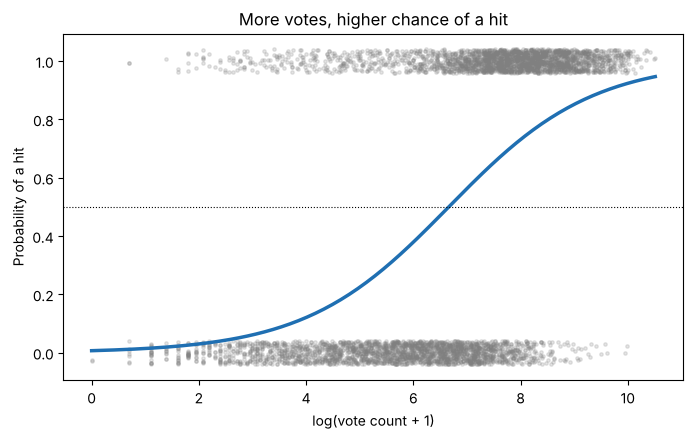

A film reaches a 50% chance of being a hit at about 781 votes


In [11]:
one = LogisticRegression().fit(X_train_l[['log_votes']], y_train_l)

grid = pd.DataFrame({'log_votes': np.linspace(X_log['log_votes'].min(), X_log['log_votes'].max(), 200)})
prob = one.predict_proba(grid)[:, 1]

jitter = np.random.default_rng(0).uniform(-0.04, 0.04, len(y))
plt.figure(figsize=(8, 4.5))
plt.scatter(X_log['log_votes'], y + jitter, s=6, alpha=0.2, color='grey')
plt.plot(grid['log_votes'], prob, color='#1f6fb2', linewidth=2.5)
plt.axhline(0.5, color='black', linewidth=0.8, linestyle=':')
plt.xlabel('log(vote count + 1)')
plt.ylabel('Probability of a hit')
plt.title('More votes, higher chance of a hit')
plt.show()

# Where does the curve cross 50%?
cross = -one.intercept_[0] / one.coef_[0][0]
print('A film reaches a 50% chance of being a hit at about', round(np.expm1(cross)), 'votes')

# Part 2: All Three Project Datasets

My project has three datasets: the box office data used above, **MovieLens 20M** (user ratings, tags, and the tag genome), and the **4 Services Streaming** catalogs (Netflix, Prime Video, Hulu, Disney+). `OMDS-ModC-DataPrep-Paliwal-Rupal.ipynb` joins them by cleaned title and release year and saves `combined_films.csv`.

MovieLens 20M ends in 2015, so Part 2 uses the **films released 2000 to 2015 that matched MovieLens**. To see what the extra datasets add, every model is fit twice on exactly the same films and split:
- **Box office only**: the same 32 features as Part 1
- **All three datasets**: those 32 plus 7 new ones: MovieLens rating count (log), MovieLens average rating, MovieLens tag count (log), and 0/1 flags for Netflix, Prime Video, Hulu, and Disney+

In [12]:
combo = pd.read_csv('combined_films.csv')     # same row order as the box office file
sub = combo.loc[X_log.index]
sub = sub[(sub['in_movielens'] == 1) & (sub['ml_n_ratings'] > 0)]

extra = pd.DataFrame({
    'ml_log_ratings': np.log1p(sub['ml_n_ratings']),   # MovieLens: how many users rated the film
    'ml_mean_rating': sub['ml_mean_rating'],            # MovieLens: average user rating (0.5 to 5 stars)
    'ml_log_tags': np.log1p(sub['ml_n_tags']),          # MovieLens: how many tags users added
    'on_netflix': sub['on_netflix'], 'on_prime': sub['on_prime'],
    'on_hulu': sub['on_hulu'], 'on_disney': sub['on_disney'],   # streaming catalogs
}, index=sub.index)

XA = X_log.loc[sub.index]               # box office only
XB = pd.concat([XA, extra], axis=1)      # all three datasets
y3 = (sub['$Worldwide'] > df['$Worldwide'].median()).astype(int)   # hit = above the median of all 5,000 films
print('Films in Part 2:', len(sub), '| years', sub['Year'].min(), 'to', sub['Year'].max())
print('Box office features:', XA.shape[1], '| all three datasets:', XB.shape[1])

Films in Part 2: 2407 | years 2000 to 2015
Box office features: 32 | all three datasets: 39


## P2.1 Logistic regression with all three datasets

Same standardized logistic regression as the final model above, fit on the same 2000 to 2015 films with and without the extra features.

In [13]:
tr3, te3 = train_test_split(XA.index, test_size=0.2, random_state=42, stratify=y3)
print('Share of hits in this subset:', round(y3.mean(), 3), '(always guessing hit would score this)')
rows, models3 = [], {}
for name, Z in [('Box office only', XA), ('All three datasets', XB)]:
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Z.loc[tr3], y3[tr3])
    models3[name] = m
    rows.append({'features': name, 'n_features': Z.shape[1], 'test_accuracy': round(accuracy_score(y3[te3], m.predict(Z.loc[te3])), 4)})
pd.DataFrame(rows)

Share of hits in this subset: 0.595 (always guessing hit would score this)


,features,n_features,test_accuracy
0,Box office only,32,0.8112
1,All three datasets,39,0.8278


In [14]:
co3 = pd.Series(models3['All three datasets'][-1].coef_[0], index=XB.columns)
new = ['ml_log_ratings', 'ml_mean_rating', 'ml_log_tags', 'on_netflix', 'on_prime', 'on_hulu', 'on_disney', 'log_votes', 'rating']
pd.DataFrame({'coefficient': co3[new], 'odds_ratio': np.exp(co3[new])}).round(2)

,coefficient,odds_ratio
ml_log_ratings,1.05,2.84
ml_mean_rating,-0.33,0.72
ml_log_tags,-0.45,0.64
on_netflix,0.13,1.14
on_prime,-0.03,0.97
on_hulu,0.11,1.12
on_disney,0.22,1.25
log_votes,2.17,8.74
rating,-0.25,0.78


## 7. Conclusions

**The model works reasonably well.** It predicts hit or not correctly for about **78%** of test films, compared with about 51% from always guessing "hit." Errors are fairly balanced: 121 films were wrongly called hits and 88 hits were missed.

**What drives a hit (odds ratios from the final model):**
- **Vote count dominates again.** One standard deviation more (log) votes multiplies the odds of a hit by about **9**. The logistic curve crosses a 50% chance at roughly 800 votes.
- **Chinese language films** have about **2.3 times** the odds of being a hit at the same vote count. This matches Week 2: Chinese films earn more than their vote count suggests, likely because the votes come from TMDB, whose users skew Western. Korean and Cantonese films show a smaller version of the same pattern, while French and Italian films are less likely to be hits.
- **Rating** has an odds ratio of about **0.75**. At the same vote count, higher rated films are *not* more likely to be hits, the same result I found in Week 2 and Module B.
- **Family** films get a small boost (odds ratio about 1.26).

**Feature scaling mattered.** Without scaling, the solver never converged. Normalization converged but lost about 4 points of accuracy because the vote outliers squeezed most films near 0. Standardization was the fastest and most reliable, which is why the final model uses it.

**Limitation:** as in Week 2, vote count is only known after release, so this model explains which films became hits rather than predicting hits in advance.

**Part 2 (all three datasets).** On the 2000 to 2015 films, adding the MovieLens and streaming features raised test accuracy by a little under 2 points. MovieLens rating count is the second strongest predictor after TMDB votes. The MovieLens average rating again has an odds ratio below 1, the same "approval doesn't add revenue" pattern seen with the TMDB rating, now confirmed by a second, independent audience. The streaming flags have small effects (odds ratios between 0.97 and 1.25), so being on a streaming service today says little about how a film did in theaters.

### Think About It

- **Why is feature scaling important to models' performance?** Two reasons, both visible above. First, regularization penalizes coefficient size, which is only fair if features share a scale. Second, the solver converges much faster on scaled features: 14 iterations with standardization versus more than 1,000 (and no convergence) without it.
- **Why does logistic regression require independent samples?** Each row should be a separate piece of evidence. If rows are near copies of each other, like a time series, the model thinks it has much more evidence than it really does and becomes overconfident. Films are mostly independent, but not perfectly: sequels and franchise entries share audiences, and films released in the same year share market conditions.
- **What is the difference between standardization and normalization?** Normalization (min max scaling) squeezes each feature into the range 0 to 1 using its minimum and maximum. Standardization shifts each feature to mean 0 and standard deviation 1. Normalization is sensitive to outliers because one extreme value sets the maximum, which is exactly what happened with vote count here. Standardization handles that better.